# load data

In [ ]:
import pandas as pd

df = pd.read_csv("../data/raw/student_mental_health.csv")

print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum().to_string())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nDuplicate Student IDs:")
print(df["Student_ID"].duplicated().sum())

print("\nNumerical Statistics:")
print(df.describe().to_string())

print("\nTarget Distribution:")
print(df["Mental_Health_Risk"].value_counts().to_string())

print("\nTarget Percentages:")
print(
    (df["Mental_Health_Risk"].value_counts(normalize=True) * 100)
    .round(2)
    .to_string()
)

SyntaxError: Expected one or more names after 'import' (1973019157.py, line 2)

# Identify Numerical & Categorical Variables

In [ ]:
categorical_cols = df.select_dtypes(include="object").columns.tolist()
numerical_cols = df.select_dtypes(include="number").columns.tolist()

print("Categorical Columns:", categorical_cols)
print("Numerical Columns:", numerical_cols)

Categorical Columns: ['Student_ID', 'Gender', 'Physical_Activity', 'Part_Time_Job', 'Diet_Quality', 'Previous_Mental_Health_History', 'Mental_Health_Risk']
Numerical Columns: ['Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress', 'Family_Support', 'Attendance_Rate']


C:\Users\dough\AppData\Local\Temp\ipykernel_36248\2328049331.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include="object").columns.tolist()


# Categorical Variables Analysis

In [ ]:
for col in categorical_cols:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False))


--- Student_ID ---
Student_ID
STU0001    1
STU0002    1
STU0003    1
STU0004    1
STU0005    1
          ..
STU1996    1
STU1997    1
STU1998    1
STU1999    1
STU2000    1
Name: count, Length: 2000, dtype: int64

--- Gender ---
Gender
Female        971
Male          932
Non-binary     97
Name: count, dtype: int64

--- Physical_Activity ---
Physical_Activity
Moderate    906
Low         679
High        415
Name: count, dtype: int64

--- Part_Time_Job ---
Part_Time_Job
No     1289
Yes     711
Name: count, dtype: int64

--- Diet_Quality ---
Diet_Quality
Average    860
Poor       587
Good       484
NaN         69
Name: count, dtype: int64

--- Previous_Mental_Health_History ---
Previous_Mental_Health_History
No     1408
Yes     592
Name: count, dtype: int64

--- Mental_Health_Risk ---
Mental_Health_Risk
High      680
Medium    660
Low       660
Name: count, dtype: int64


# Numerical Features vs Target

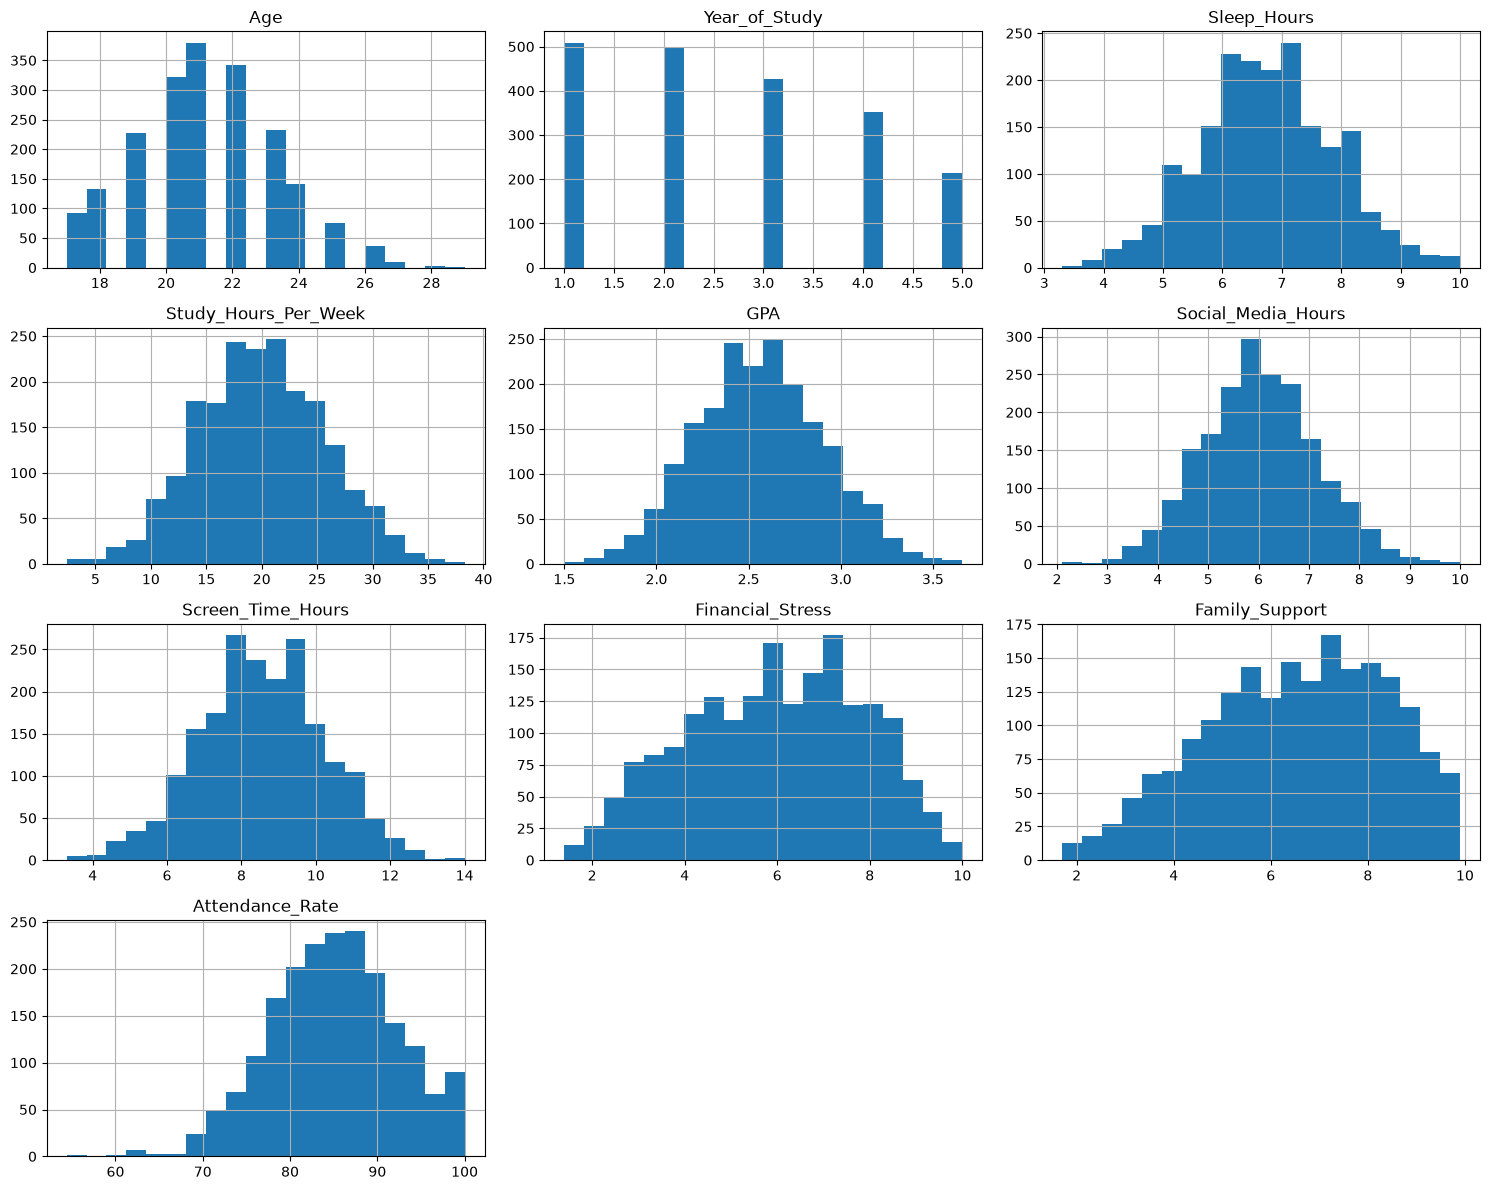

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

df[numerical_cols].hist(
    figsize=(15, 12),
    bins=20
)

plt.tight_layout()
plt.show()

# Correlation Matrix

In [ ]:
correlation = df[numerical_cols].corr(method="pearson")

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

# Categorical Features vs Target

In [ ]:
for col in categorical_cols:
    if col in ["Student_ID", "Mental_Health_Risk"]:
        continue

    plt.figure(figsize=(8, 4))

    sns.countplot(
        data=df,
        x=col,
        hue="Mental_Health_Risk"
    )

    plt.title(f"{col} vs Mental Health Risk")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()